In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("winequalityN.csv")

In [3]:
df.shape

(6497, 13)

In [4]:
df.head()

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [5]:
df['type'].value_counts() /len(df)*100

type
white    75.388641
red      24.611359
Name: count, dtype: float64

In [6]:
df['type'] = df['type'].map({'white': 0, 'red': 1})
df = df.sample(frac=1, random_state=20).reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   type                  6497 non-null   int64  
 1   fixed acidity         6487 non-null   float64
 2   volatile acidity      6489 non-null   float64
 3   citric acid           6494 non-null   float64
 4   residual sugar        6495 non-null   float64
 5   chlorides             6495 non-null   float64
 6   free sulfur dioxide   6497 non-null   float64
 7   total sulfur dioxide  6497 non-null   float64
 8   density               6497 non-null   float64
 9   pH                    6488 non-null   float64
 10  sulphates             6493 non-null   float64
 11  alcohol               6497 non-null   float64
 12  quality               6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [7]:
df.isna().sum()

type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64

In [8]:
df = df.dropna()
df.isna().sum()

type                    0
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,0,5.8,0.24,0.44,3.5,0.029,5.0,109.0,0.99130,3.53,0.43,11.7,3
1,0,7.1,0.21,0.30,1.4,0.037,45.0,143.0,0.99320,3.13,0.33,9.9,6
2,1,8.3,0.42,0.38,2.5,0.094,24.0,60.0,0.99790,3.31,0.70,10.8,6
3,0,6.7,0.26,0.26,4.1,0.073,36.0,202.0,0.99560,3.30,0.67,9.5,5
4,1,9.0,0.40,0.41,2.0,0.058,15.0,40.0,0.99414,3.22,0.60,12.2,6


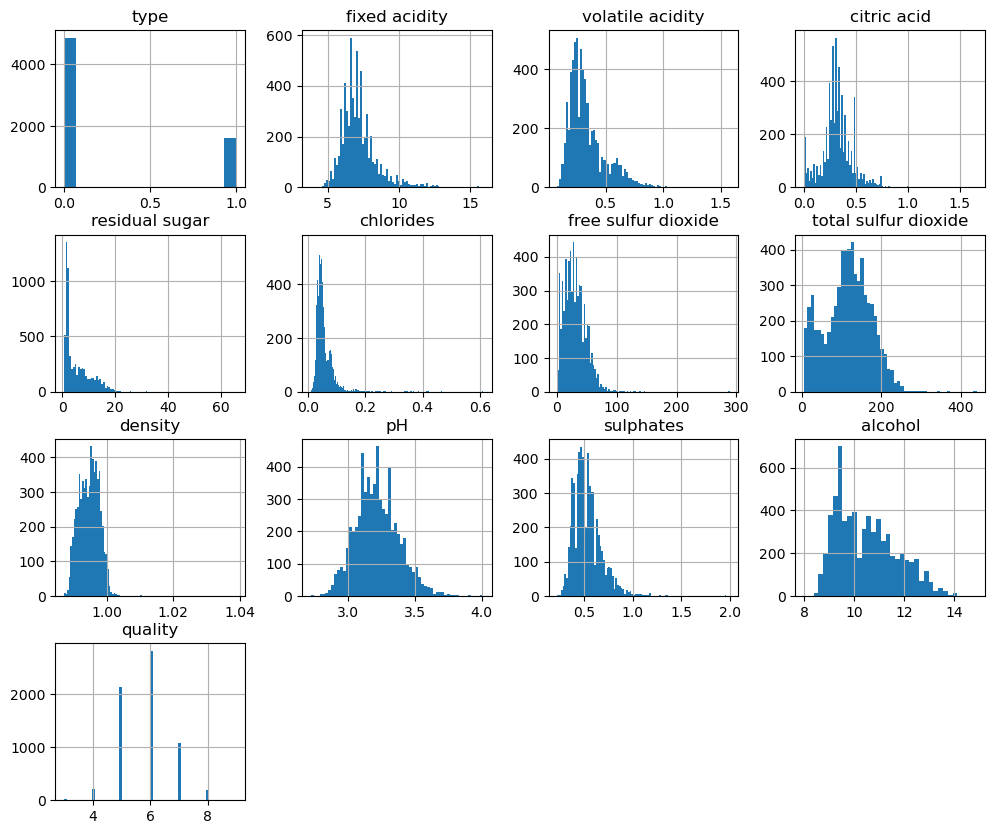

In [9]:
df.select_dtypes(include='number').hist(bins='auto', figsize=(12,10))
df.head()

In [10]:
# Train Test split 80/20
train_size = int(0.8 * len(df))
df_train = df[:train_size]
df_test = df[train_size:]

In [11]:
X_train= df_train.iloc[:,:-1]
# print(X_train.head())
Y_train= df_train.iloc[:,-1]
print(Y_train.head())

X_test= df_test.iloc[:,:-1]
Y_test= df_test.iloc[:,-1]

0    3
1    6
2    6
3    5
4    6
Name: quality, dtype: int64


In [12]:
cols_to_scale = X_train.columns[1:]
print(cols_to_scale)

print(X_train[cols_to_scale].mean())
X_train[cols_to_scale] = (X_train[cols_to_scale]-X_train[cols_to_scale].mean())/X_train[cols_to_scale].std()

X_test[cols_to_scale] = (X_test[cols_to_scale]-X_train[cols_to_scale].mean())/X_train[cols_to_scale].std()


Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol'],
      dtype='object')
fixed acidity             7.218433
volatile acidity          0.339406
citric acid               0.317472
residual sugar            5.443936
chlorides                 0.055861
free sulfur dioxide      30.557834
total sulfur dioxide    115.605126
density                   0.994693
pH                        3.217398
sulphates                 0.531739
alcohol                  10.498369
dtype: float64


In [13]:
arr = np.array([3,4,5,6,7,8,9])
value = 7

idx = np.where(arr == value)[0][0]

print(idx) 

4


In [14]:
# print(Y_train)
print(Y_train.shape)

print(Y_train.value_counts() /len(Y_train)*100)


# Encoding 
# Sorted unique classes
unique_classes = np.sort(df['quality'].unique())   # [3 4 5 6 7 8 9] # [R G B]

# Map y_train labels to (0,..,6)
# np.where(unique_classes == a)[0][0] gives the index of 'a' in unique_classes array
mapped_Y_train = np.array([np.where(unique_classes == a)[0][0] for a in Y_train]) 
print(mapped_Y_train)
print(mapped_Y_train.shape) # (m,)

# one-hot encoded matrix
Y_train_encoded = np.eye(len(unique_classes))[mapped_Y_train]  # (m,k)
print(Y_train_encoded)




(5170,)
quality
6    43.365571
5    32.804642
7    16.673114
4     3.481625
8     3.056093
3     0.560928
9     0.058027
Name: count, dtype: float64
[0 3 3 ... 2 2 4]
(5170,)
[[1. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 [0. 0. 0. ... 1. 0. 0.]]


In [15]:
print(X_train.head())
print(Y_train_encoded)
print(X_train.shape)
print(Y_train_encoded.shape)

   type  fixed acidity  volatile acidity  citric acid  residual sugar  \
0     0      -1.094760         -0.599898     0.845545       -0.407397   
1     0      -0.091408         -0.780943    -0.120571       -0.847501   
2     1       0.834763          0.486369     0.431496       -0.616970   
3     0      -0.400132         -0.479202    -0.396604       -0.281653   
4     1       1.375030          0.365673     0.638520       -0.721757   

   chlorides  free sulfur dioxide  total sulfur dioxide   density        pH  \
0  -0.786258            -1.435044             -0.116318 -1.125341  1.939671   
1  -0.552086             0.810912              0.482430 -0.495243 -0.542301   
2   1.116385            -0.368215             -0.979219  1.063419  0.574586   
3   0.501685             0.305572              1.521434  0.300669  0.512537   
4   0.062614            -0.873555             -1.331424 -0.183511  0.016142   

   sulphates   alcohol  
0  -0.686015  1.009208  
1  -1.360305 -0.502550  
2   1.13456

In [16]:
m=X_train.shape[0]
n=X_train.shape[1]
k=Y_train_encoded.shape[1]
m,n,k

(5170, 12, 7)

MULTICLASS CLASSIFICATION SOFTMAX

In [22]:
w = np.zeros((n, k))
b = np.zeros((1, k))

def softmax(z):
    z=np.asarray(z) # (m x k)
    z = z - np.max(z, axis=1, keepdims=True)   # stability trick
    sm = np.exp(z) / np.sum(np.exp(z), axis=1, keepdims=True) # (m x k) / (m x 1) = (m x k)
    return sm

# Cost function (softmax) J_wb
def J_wb(X,w,b,y):
    m=X.shape[0]
    z = (X @ w) + b           # (m x n @ n x k  +  1 x k) = (m x k)
    predictions = softmax(z)  # (m x k)
    cost = (-1/m)* np.sum(y*np.log(predictions + 1e-9))
    return cost

# gradient_descent_algorithm
def fit_via_gd(X,w,b,y,alpha=0.0001,epsilon=1e-7,max_epochs=1e5):
    m=X.shape[0]
    cost_history=[]
    prev_cost = float('inf')

    for i in range(max_epochs):

        if i==3000:
            alpha=0.001

        z =X @ w + b            # (m x n @ n x k) = (m x k)
        predictions = softmax(z)# (m x k)
        error=predictions-y     # (m x k)
        dw=(1/m)*(X.T @ error)  # (n x m @ m x k) = (n x k) 
        db=(1/m)* np.sum(error, axis=0, keepdims=True) # np.sum(m x k) = 1 x k
        w= w - (alpha * dw)     # (n x k)
        b= b - (alpha * db)     # (1 x k)
        
        curr_cost = J_wb(X, w, b , y)
        cost_history.append(curr_cost)

        if abs(curr_cost - prev_cost)<epsilon:
            print("Cost frunction is converged at epoch-", i, " with final cost = ", curr_cost, " bcoz the cost is not updating >= epsilon")
            break
        if i==max_epochs-1:
            print("Cost frunction is converged at epoch-", max_epochs, " with final cost = ", curr_cost, " bcoz max epochs reached")
            break

        prev_cost= curr_cost

        # Update live plot every 10 epochs
        if i % 1000 == 0:
            print("Epoch no.: ",i, ", Current Cost: ",curr_cost)


    return w,b,cost_history




In [23]:
w_final, b_final, costhistory = fit_via_gd(X_train,w,b,Y_train_encoded,alpha=0.01,epsilon=1e-7,max_epochs=int(5e5))
print("Final weights:", w_final)
print("Final bias:", b_final)


Epoch no.:  0 , Current Cost:  1.9428751052854705
Epoch no.:  1000 , Current Cost:  1.1985976378884633
Epoch no.:  2000 , Current Cost:  1.137363852352414
Epoch no.:  3000 , Current Cost:  1.1169424144068723
Epoch no.:  4000 , Current Cost:  1.1156073497587655
Epoch no.:  5000 , Current Cost:  1.1143522895647229
Epoch no.:  6000 , Current Cost:  1.1131699015364278
Epoch no.:  7000 , Current Cost:  1.1120537326888558
Epoch no.:  8000 , Current Cost:  1.1109980818874206
Epoch no.:  9000 , Current Cost:  1.1099978938470594
Epoch no.:  10000 , Current Cost:  1.1090486704840579
Epoch no.:  11000 , Current Cost:  1.1081463963960771
Epoch no.:  12000 , Current Cost:  1.107287475915463
Epoch no.:  13000 , Current Cost:  1.1064686796973773
Epoch no.:  14000 , Current Cost:  1.1056870992055978
Epoch no.:  15000 , Current Cost:  1.104940107772865
Epoch no.:  16000 , Current Cost:  1.1042253271601425
Epoch no.:  17000 , Current Cost:  1.103540598735472
Epoch no.:  18000 , Current Cost:  1.10288395

In [24]:
z_predctions = X_test @ w_final + b_final
Y_predctions = softmax(z_predctions)

# two line decoding (very easy)
y_pred_idx = np.argmax(Y_predctions, axis=1) # (m,) Row-wise max (per sample)
y_pred_real = unique_classes[y_pred_idx] # (m,)

new_df = pd.DataFrame({
    "Predicted diagnosis": y_pred_real,
    "Actual diagonosis": Y_test
})
new_df


,Predicted diagnosis,Actual diagonosis
5200,3,5
5201,3,6
5202,3,5
5203,5,6
5204,5,7
...,...,...
6492,8,5
6493,3,7
6494,3,7
6495,5,5


In [27]:
accuracy = np.mean(y_pred_real == Y_test)

print("Test Accuracy: ", accuracy)

Test Accuracy:  0.22351121423047177


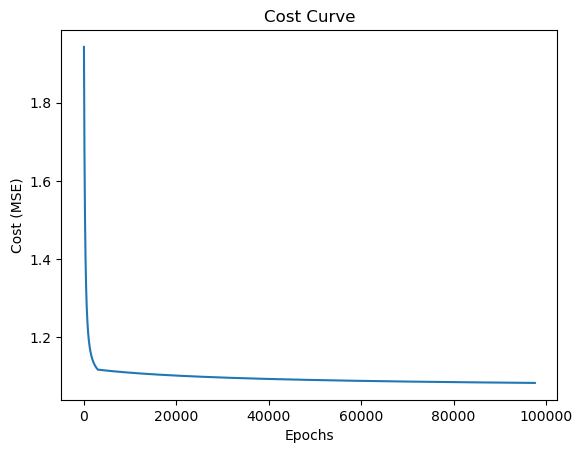

In [28]:
plt.plot(costhistory)
plt.xlabel("Epochs")
plt.ylabel("Cost (MSE)")
plt.title("Cost Curve")
plt.show()

